In [33]:
# ДЗ 2
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Выяснить, какой фильтр показал лучший результат фильтрации шума.

In [34]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim, mean_squared_error

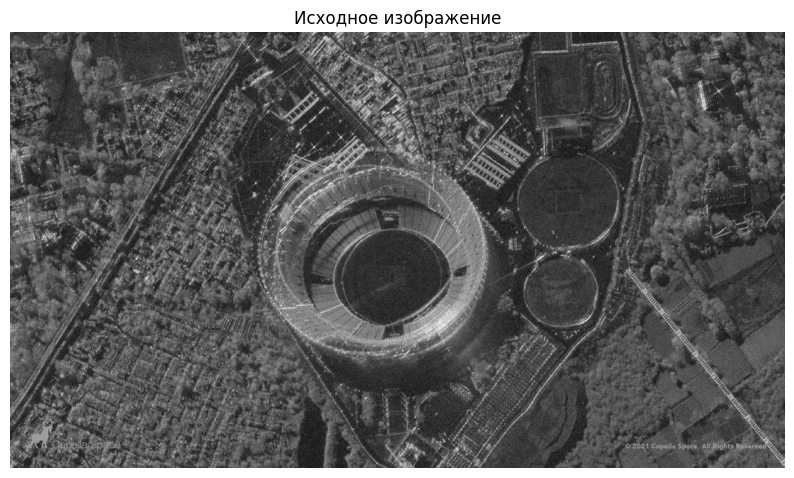

In [35]:

image = cv2.imread('sar_1.jpg')

if image is None:
    raise FileNotFoundError("Не найден файл sar_1.jpg")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

## Шум Гаусса

In [36]:

mean = 0
stddev = 30

cv2.setRNGSeed(42)
noise_gauss = np.zeros(image_gray.shape, dtype=np.float32)
cv2.randn(noise_gauss, mean, stddev)


array([[ 7.24996596e-07, -1.87754040e+01,  1.76497231e+01, ...,
         4.35242081e+01, -4.04667778e+01, -8.71733284e+00],
       [-9.68666673e-02,  5.17184496e+00,  5.24901342e+00, ...,
         1.21379995e+01, -1.09467039e+01,  9.59307671e+00],
       [ 7.09272909e+00,  3.42921715e+01, -7.46461821e+00, ...,
        -4.14379072e+00,  2.09121304e+01, -7.27418327e+00],
       ...,
       [ 1.51299725e+01, -2.94135799e+01,  6.17410240e+01, ...,
         7.68493366e+00, -8.01046848e+00,  1.06381035e+01],
       [ 5.47494583e+01, -1.14013767e+01,  3.89350623e-01, ...,
        -3.34133453e+01,  9.74358940e+00, -4.87655869e+01],
       [ 2.75423546e+01, -1.88977871e+01,  5.09559555e+01, ...,
        -1.02584248e+01,  2.34379816e+00,  2.38235741e+01]], dtype=float32)

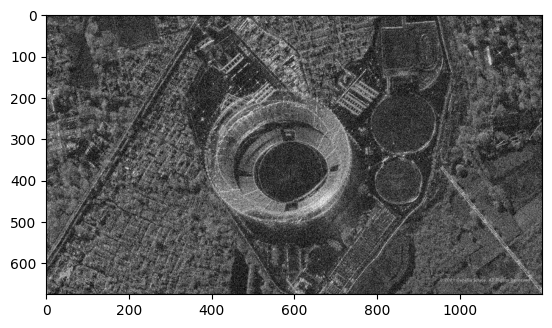

In [37]:
noisy_image = image_gray.astype(np.float32) + noise_gauss
noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)
plt.imshow(noisy_image, cmap='gray')

## Постоянный (равномерный) шум

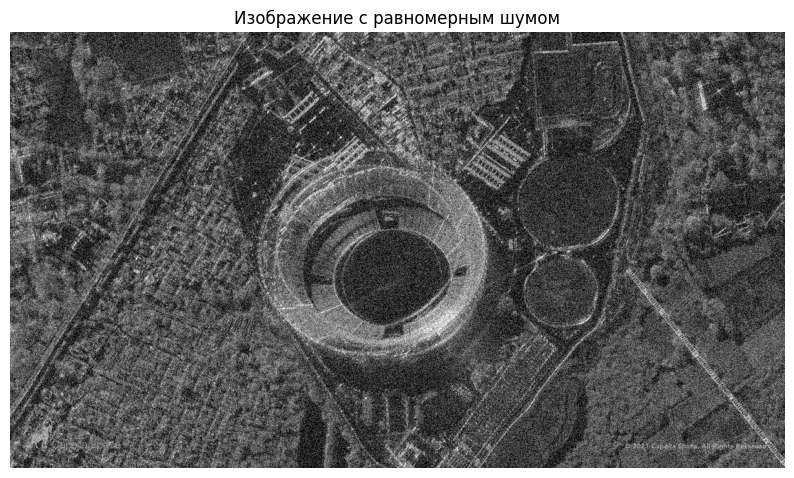

In [38]:

a = -50
b = 50

rng = np.random.default_rng(42)
noise_uniform = rng.uniform(a, b, image_gray.shape).astype(np.float32)
noisy_image_uniform = (image_gray.astype(np.float32) + noise_uniform)
noisy_image_uniform = np.clip(noisy_image_uniform, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 6))
plt.imshow(noisy_image_uniform, cmap='gray', vmin=0, vmax=255)
plt.title('Изображение с равномерным шумом')
plt.axis('off')
plt.show()


## Тестирование алгоритмов подавления шума Гаусса

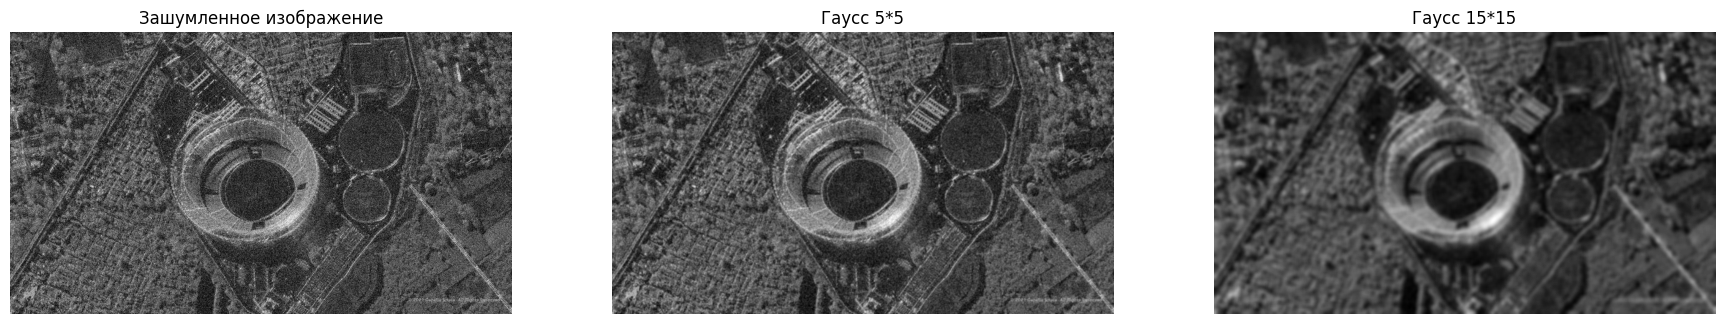

In [39]:
mse_values = []
ssim_values = []
plt.figure(figsize=(22, 6))
plt.subplot(1,3,1)
plt.imshow(noisy_image, cmap='gray')
plt.axis('off')
plt.title('Зашумленное изображение')
plt.subplot(1,3,2)
image_gauss_gauss = cv2.GaussianBlur(noisy_image, (5, 5), 0)
plt.axis('off')
plt.title('Гаусс 5*5')
plt.imshow(image_gauss_gauss, cmap='gray')
plt.subplot(1,3,3)
image_gauss_gauss1 = cv2.GaussianBlur(noisy_image, (15, 15), 5)
plt.axis('off')
plt.title('Гаусс 15*15')
plt.imshow(image_gauss_gauss1, cmap='gray')

In [40]:
mse_gauss = mean_squared_error(image_gray, image_gauss_gauss)
(ssim_gauss, diff) = ssim(image_gray, image_gauss_gauss, full=True)
mse_values.append(mse_gauss)
ssim_values.append(ssim_gauss)
print(mse_gauss, ssim_gauss)

176.88734814814813 0.6766204486820742


## Медианный фильтр

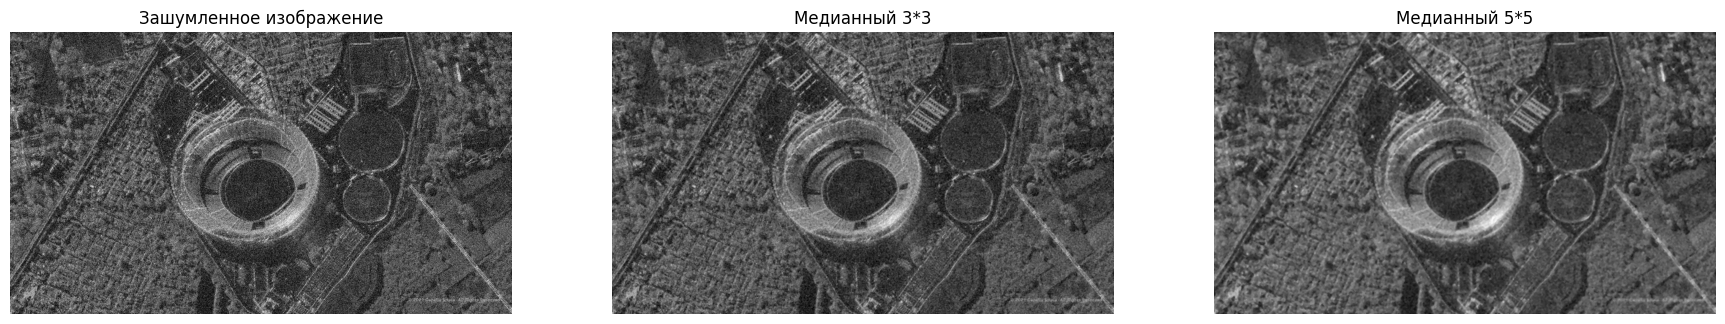

In [41]:
plt.figure(figsize=(22, 6))

plt.subplot(1, 3, 1)
plt.imshow(noisy_image, cmap='gray')
plt.axis('off')
plt.title('Зашумленное изображение')

plt.subplot(1, 3, 2)
image_gauss_median = cv2.medianBlur(noisy_image, 3)
plt.imshow(image_gauss_median, cmap='gray')
plt.axis('off')
plt.title('Медианный 3*3')

plt.subplot(1, 3, 3)
image_gauss_median1 = cv2.medianBlur(noisy_image, 5)
plt.imshow(image_gauss_median1, cmap='gray')
plt.axis('off')
plt.title('Медианный 5*5')

plt.show()

In [42]:
mse_median = mean_squared_error(image_gray, image_gauss_median)

(ssim_median, diff) = ssim(
    image_gray,
    image_gauss_median,
    full=True
)

mse_values.append(mse_median)
ssim_values.append(ssim_median)

print(mse_median, ssim_median)

258.9386901234568 0.5892536166907719


## Билатеральный фильтр

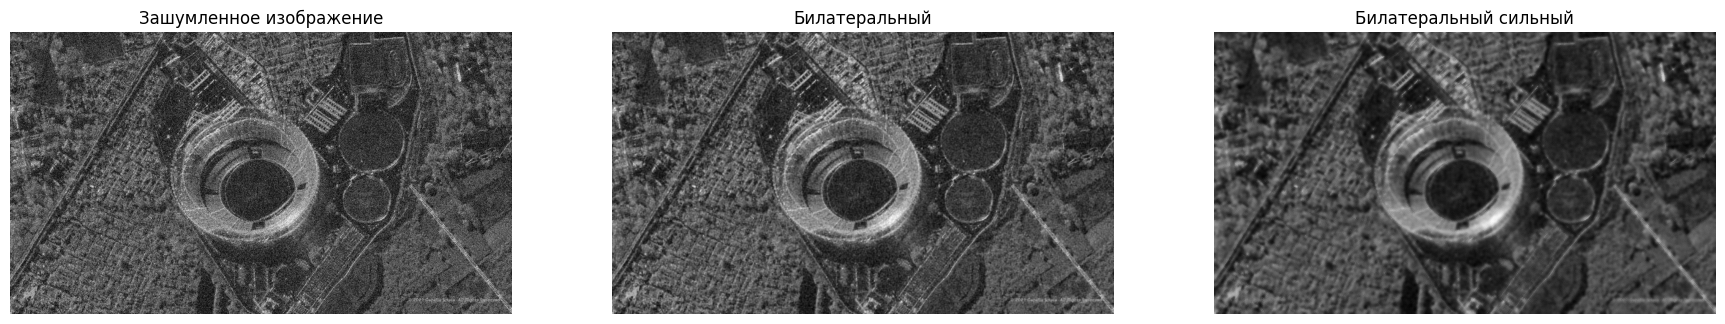

In [43]:
plt.figure(figsize=(22, 6))
plt.subplot(1,3,1)
plt.imshow(noisy_image, cmap='gray')
plt.axis('off')
plt.title('Зашумленное изображение')
plt.subplot(1,3,2)
image_gauss_bilat = cv2.bilateralFilter(noisy_image, 5, 75, 75)
plt.imshow(image_gauss_bilat, cmap='gray')
plt.axis('off')
plt.title('Билатеральный')
plt.subplot(1,3,3)
image_gauss_bilat1 = cv2.bilateralFilter(noisy_image, 10, 100, 100)
plt.imshow(image_gauss_bilat1, cmap='gray')
plt.axis('off')
plt.title('Билатеральный сильный')
plt.show()

In [44]:
mse_bilat = mean_squared_error(image_gray, image_gauss_bilat)
(ssim_bilat, diff) = ssim(image_gray, image_gauss_bilat, full=True)
mse_values.append(mse_bilat)
ssim_values.append(ssim_bilat)
print(mse_bilat, ssim_bilat)

186.8786851851852 0.6646623513332666


## Фильтр нелокальных средних

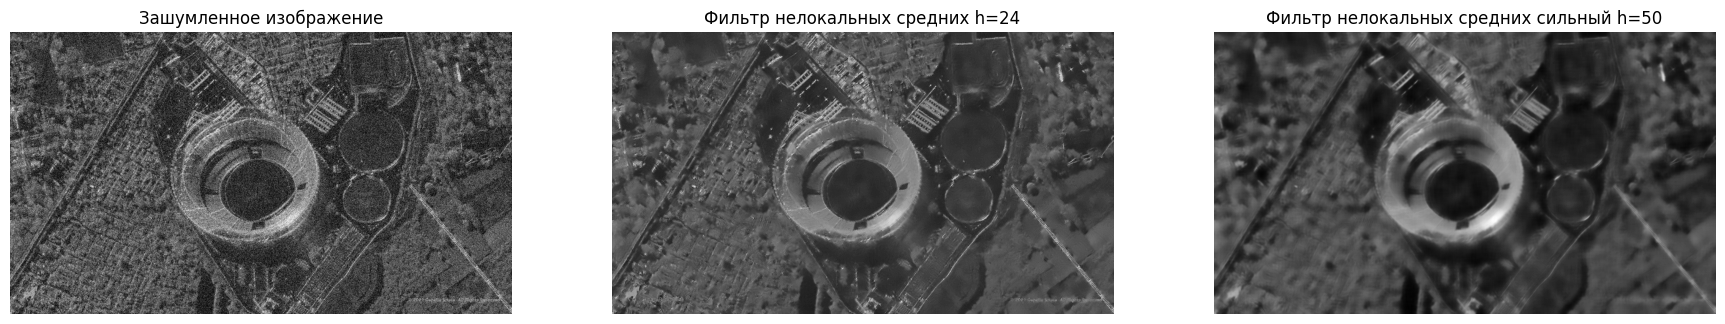

In [45]:
plt.figure(figsize=(22, 6))
plt.subplot(1,3,1)
plt.imshow(noisy_image, cmap='gray')
plt.axis('off')
plt.title('Зашумленное изображение')
plt.subplot(1,3,2)
image_gauss_nlm = cv2.fastNlMeansDenoising(noisy_image, h = 24)
plt.imshow(image_gauss_nlm, cmap='gray')
plt.axis('off')
plt.title('Фильтр нелокальных средних h=24')
plt.subplot(1,3,3)
image_gauss_nlm1 = cv2.fastNlMeansDenoising(noisy_image, h = 50)
plt.imshow(image_gauss_nlm1, cmap='gray')
plt.axis('off')
plt.title('Фильтр нелокальных средних сильный h=50')
plt.show()

In [46]:
mse_nlm = mean_squared_error(image_gray, image_gauss_nlm,)
(ssim_nlm, diff) = ssim(image_gray, image_gauss_nlm, full=True)
mse_values.append(mse_nlm)
ssim_values.append(ssim_nlm)
print(mse_nlm, ssim_nlm)

209.11676666666668 0.6132542837901126


## Сравнение фильтров


ГАУССОВСКИЙ ШУМ
-----------------------------------------------------------------
До фильтрации: MSE = 864.99, SSIM = 0.4057

Фильтр                                  MSE       SSIM
-----------------------------------------------------------------
Гаусса 5x5                           176.89     0.6766
Гаусса 15x15                         389.04     0.3503
Медианный 3x3                        258.94     0.5893
Медианный 5x5                        260.05     0.5378
Билатеральный d=5                    186.88     0.6647
Билатеральный d=10                   260.37     0.5241
Нелокальных средних h=24             209.12     0.6133
Нелокальных средних h=50             375.78     0.3782

Лучший по MSE: Гаусса 5x5
MSE = 176.89

Лучший по SSIM: Гаусса 5x5
SSIM = 0.6766


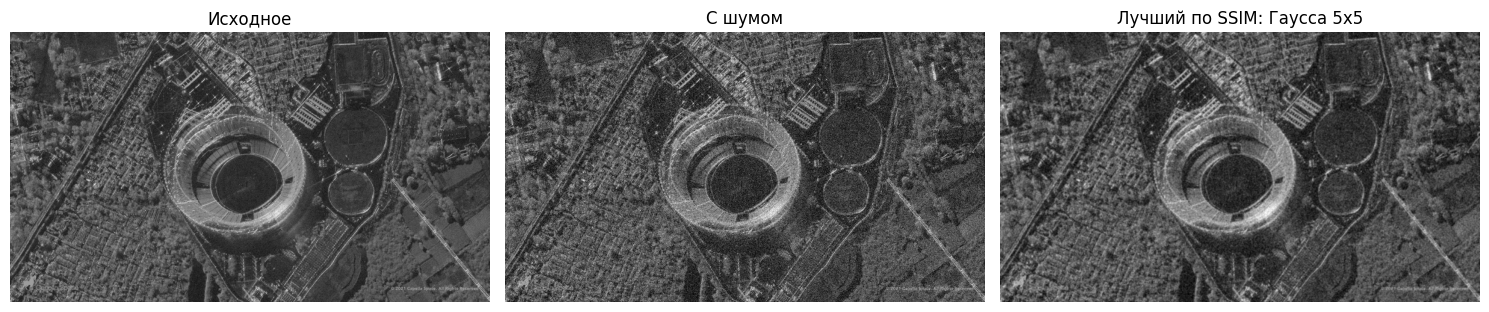

In [47]:
def compare_filters(noisy, results, noise_name):
    print('\n' + noise_name)
    print('-' * 65)

    mse_before = mean_squared_error(image_gray, noisy)
    ssim_before = ssim(image_gray, noisy)

    print(f'До фильтрации: MSE = {mse_before:.2f}, 'f'SSIM = {ssim_before:.4f}')
    print()

    scores = []

    print(f'{"Фильтр":32s} {"MSE":>10s} {"SSIM":>10s}')
    print('-' * 65)

    for name, filtered_image in results:
        mse_value = mean_squared_error(image_gray, filtered_image)
        ssim_value = ssim(image_gray, filtered_image)

        scores.append((name, mse_value, ssim_value, filtered_image))

        print(f'{name:32s} {mse_value:10.2f} ' f'{ssim_value:10.4f}')


    best_mse = min(scores, key=lambda x: x[1])
    best_ssim = max(scores, key=lambda x: x[2])

    print('\nЛучший по MSE:', best_mse[0])
    print(f'MSE = {best_mse[1]:.2f}')
    print('\nЛучший по SSIM:', best_ssim[0])
    print(f'SSIM = {best_ssim[2]:.4f}')



    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image_gray, cmap='gray')
    plt.title('Исходное')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(noisy, cmap='gray')
    plt.title('С шумом')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(best_ssim[3], cmap='gray')
    plt.title('Лучший по SSIM: ' + best_ssim[0])
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return best_mse, best_ssim



results_gauss = [
    ('Гаусса 5x5', image_gauss_gauss),
    ('Гаусса 15x15', image_gauss_gauss1),
    ('Медианный 3x3', image_gauss_median),
    ('Медианный 5x5', image_gauss_median1),
    ('Билатеральный d=5', image_gauss_bilat),
    ('Билатеральный d=10', image_gauss_bilat1),
    ('Нелокальных средних h=24', image_gauss_nlm),
    ('Нелокальных средних h=50', image_gauss_nlm1)
]

best_gauss_mse, best_gauss_ssim = compare_filters(
    noisy_image,
    results_gauss,
    'ГАУССОВСКИЙ ШУМ'
)


## Тестирование фильтров для равномерного шума


РАВНОМЕРНЫЙ ШУМ
-----------------------------------------------------------------
До фильтрации: MSE = 823.50, SSIM = 0.4157

Фильтр                                  MSE       SSIM
-----------------------------------------------------------------
Гаусса 5x5                           172.27     0.6834
Гаусса 15x15                         387.64     0.3513
Медианный 3x3                        311.05     0.5431
Медианный 5x5                        283.85     0.5097
Билатеральный d=5                    182.42     0.6704
Билатеральный d=10                   258.45     0.5269
Нелокальных средних h=24             197.75     0.6199
Нелокальных средних h=50             373.30     0.3802

Лучший по MSE: Гаусса 5x5
MSE = 172.27

Лучший по SSIM: Гаусса 5x5
SSIM = 0.6834


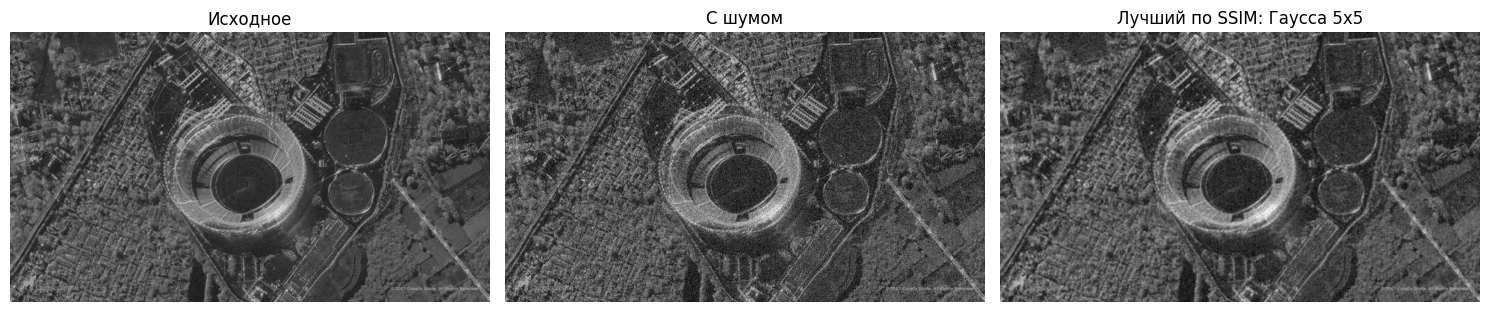

In [48]:
uniform_gauss_5 = cv2.GaussianBlur(noisy_image_uniform, (5, 5), 0)
uniform_gauss_15 = cv2.GaussianBlur(noisy_image_uniform, (15, 15), 5)

uniform_median_3 = cv2.medianBlur(noisy_image_uniform, 3)
uniform_median_5 = cv2.medianBlur(noisy_image_uniform, 5)

uniform_bilat_5 = cv2.bilateralFilter(noisy_image_uniform, 5, 75, 75)
uniform_bilat_10 = cv2.bilateralFilter(noisy_image_uniform, 10, 100, 100)

uniform_nlm_24 = cv2.fastNlMeansDenoising(noisy_image_uniform, h=24)
uniform_nlm_50 = cv2.fastNlMeansDenoising(noisy_image_uniform, h=50)


results_uniform = [
    ('Гаусса 5x5', uniform_gauss_5),
    ('Гаусса 15x15', uniform_gauss_15),
    ('Медианный 3x3', uniform_median_3),
    ('Медианный 5x5', uniform_median_5),
    ('Билатеральный d=5', uniform_bilat_5),
    ('Билатеральный d=10', uniform_bilat_10),
    ('Нелокальных средних h=24', uniform_nlm_24),
    ('Нелокальных средних h=50', uniform_nlm_50)
]

best_uniform_mse, best_uniform_ssim = compare_filters(
    noisy_image_uniform,
    results_uniform,
    'РАВНОМЕРНЫЙ ШУМ'
)